# Pretraining and the data scaling law (CNN, MNIST)
Target task: digits **3, 5, 8** (3-way; confusable digits, so the error stays above
test-set resolution). Generalization (test error and test cross-entropy) as a function of
target training set size $m$, trained from scratch vs. fine-tuned from a CNN pretrained on
other digits. Levels of pretraining (all images of each source set):
- **2 digits**: 2, 7 (~12k images)
- **4 digits**: 0, 2, 4, 7 (~24k)
- **all digits**: the 7 non-target digits 0, 1, 2, 4, 6, 7, 9 (~42k) + a small fixed subset of
  the target digits (300 images per class; artificial upper level). These held-out target images
  are removed from the target training pool for *every* condition.
- **all digits + aug**: same data, with random affine augmentation (rotation, scale, shift)
  during pretraining

**Part 1** runs the simulation (code in `theory.py`) and saves every curve to `sim_dir`
(`data/simulation/mnist_pretrain/`, see its README for the file format);
**Part 2** only loads the saved results and does the analysis (no training, no GPU needed).
Run the setup cells below, then either part.

In [1]:
# imports (shared by both parts; torch is imported in Part 1)
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

from utils import PACBayesCurve

In [2]:
# figure formating
import seaborn as sns
custom_params = {"axes.spines.right": False,
                 "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['figure.dpi'] = 100   # display
mpl.rcParams['savefig.dpi'] = 300  # saved figures

In [3]:
# settings shared by simulation and analysis
sim_dir = './data/simulation/mnist_pretrain'  # simulated learning curves (released)
cache_dir = './cache/nn_pretrain_358_mix300'  # pretrained networks (intermediate, not released)
target_digits = [3, 5, 8]
n_repeat = 8

# conditions in order of increasing pretraining
conditions = ['scratch', 'pretrain 2 digits', 'pretrain 4 digits',
              'pretrain all digits', 'pretrain all digits + aug']
curve_path = lambda cond: f"{sim_dir}/target_{cond.replace(' + aug', ' waug').replace(' ', '_')}.npz"

---
## Part 1: Simulation
Simulation code (data, CNN, training, pretraining, `NetworkCurve`) is in `theory.py`.

Fine-tuning: pretrained conv + fc features, **new random head** (source and target
labels differ; for *all digits* the pretrained 3/5/8 outputs are also discarded), all weights trained.

Training protocol: same learner at every $m$ (AdamW + cosine decay), trained to
approximate convergence: `max(min_steps, min_epochs)` SGD steps.
Averaged over random target subsets + initializations (one pretrained network per repeat).
Results are cached: re-running a cell with an existing results / cache file loads it instead of training.

In [4]:
import torch
from theory import (device, load_mnist, split_digits, hold_out_per_class, merge_sources,
                    augment, CNN, NetworkCurve, pretrain, pretrained_init)

torch.backends.cudnn.benchmark = True
print(device)

cuda


### Data

In [5]:
mnist = load_mnist()

source_digits = {'7 digits': [0, 1, 2, 4, 6, 7, 9],
                 '4 digits': [0, 2, 4, 7],
                 '2 digits': [2, 7]}
n_mix = 300  # target images per class mixed into the 'all digits' pretraining set

# fixed held-out subset of the target training set (n_mix per class) for the 'all digits'
# level; removed from the target training pool of every condition
target, target_mix = hold_out_per_class(split_digits(mnist, target_digits), n_mix)

sources = {k: split_digits(mnist, d) for k, d in source_digits.items()}

print('target', target_digits, 'train pool', len(target[0]), 'held out', len(target_mix[0]),
      'test', len(target[2]))
for k, d in sources.items():
    print('source', k, source_digits[k], 'train', len(d[0]), 'test', len(d[2]))

target [3, 5, 8] train pool 16503 held out 900 test 2876
source 7 digits [0, 1, 2, 4, 6, 7, 9] train 42597 test 7124
source 4 digits [0, 2, 4, 7] train 23988 test 4022
source 2 digits [2, 7] train 12223 test 2060


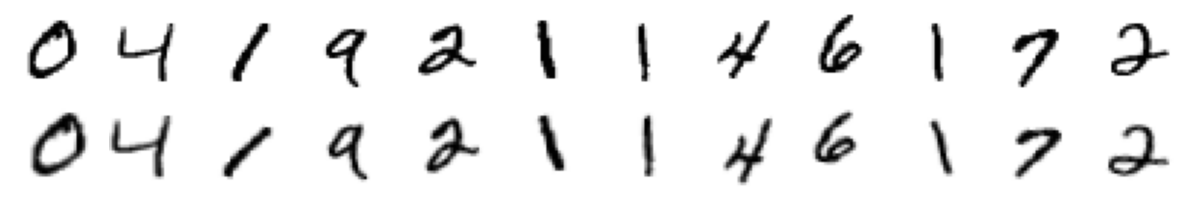

In [6]:
# a few source images (top) and their augmented versions (bottom)
torch.manual_seed(0)
X_s = sources['7 digits'][0][:12]
fig, axs = plt.subplots(2, 12, figsize=(12, 2.3))
for row, imgs in zip(axs, (X_s, augment(X_s))):
    for ax, img in zip(row, imgs):
        ax.imshow(img[0].cpu(), cmap='gray_r')
        ax.axis('off')
plt.tight_layout()
plt.show()

### Pretraining

In [7]:
n7 = len(source_digits['7 digits'])
all_digits = merge_sources(sources['7 digits'], target_mix, n7)
levels = {  # name: (pretraining data, n_classes, train kwargs)
    '2 digits': (sources['2 digits'], len(source_digits['2 digits']), {}),
    '4 digits': (sources['4 digits'], len(source_digits['4 digits']), {}),
    'all digits': (all_digits, n7 + len(target_digits), {}),
    'all digits + aug': (all_digits, n7 + len(target_digits), {'augment': augment}),
}

pretrained = {}
for k, (d, n_classes, kw) in levels.items():
    print(f'--- source {k} ({len(d[0])} images, {n_classes} classes)')
    pretrained[k] = pretrain(d, n_classes=n_classes, n_repeat=n_repeat,
                             cache=f"{cache_dir}/pretrain_{k.replace(' ', '_')}.pt", **kw)

--- source 2 digits (12223 images, 2 classes)
loaded ./cache/nn_pretrain_358_mix300/pretrain_2_digits.pt
--- source 4 digits (23988 images, 4 classes)
loaded ./cache/nn_pretrain_358_mix300/pretrain_4_digits.pt
--- source all digits (43497 images, 10 classes)
loaded ./cache/nn_pretrain_358_mix300/pretrain_all_digits.pt
--- source all digits + aug (43497 images, 10 classes)
loaded ./cache/nn_pretrain_358_mix300/pretrain_all_digits_+_aug.pt


### Scratch vs. fine-tune

In [8]:
train_size = 2 ** np.arange(4, 15)
cnn_target = lambda: CNN(n_classes=len(target_digits))

inits = {'scratch': None}
inits.update({f'pretrain {k}': pretrained_init(s) for k, s in pretrained.items()})
assert list(inits) == conditions

for cond, init in inits.items():
    print(f'--- {cond}')
    cc = NetworkCurve(target, cnn_target, init=init, train_size=train_size, n_repeat=n_repeat)
    cc.run(cache=curve_path(cond))

--- scratch
loaded ./data/simulation/mnist_pretrain/target_scratch.npz
--- pretrain 2 digits
loaded ./data/simulation/mnist_pretrain/target_pretrain_2_digits.npz
--- pretrain 4 digits
loaded ./data/simulation/mnist_pretrain/target_pretrain_4_digits.npz
--- pretrain all digits
loaded ./data/simulation/mnist_pretrain/target_pretrain_all_digits.npz
--- pretrain all digits + aug
loaded ./data/simulation/mnist_pretrain/target_pretrain_all_digits_waug.npz


---
## Part 2: Analysis of the saved results
Loads the curves saved by Part 1 (`sim_dir`); only the setup cells above are needed.

In [9]:
class SavedCurve:
    '''
    Results of one NetworkCurve run, loaded from its cache file:
    per (m, repeat) test error / cross-entropy, and their mean / sd over repeats.
    '''
    def __init__(self, path):
        res = np.load(path)
        self.train_size = res['train_size']
        self.errors, self.losses = res['errors'], res['losses']
        self.train_errors = res['train_errors']
        self.error, self.error_sd = self.errors.mean(axis=1), self.errors.std(axis=1)
        self.loss, self.loss_sd = self.losses.mean(axis=1), self.losses.std(axis=1)


# conditions analysed (all digits + aug left out for now)
analysis = ['scratch', 'pretrain 2 digits', 'pretrain 4 digits', 'pretrain all digits']
curves = {cond: SavedCurve(curve_path(cond)) for cond in analysis}

# scratch in blue -> pretraining levels towards green (blue, cyan, light green, green)
colors = dict(zip(analysis, ['tab:blue', 'tab:cyan', '#7fc97f', 'tab:green']))
for k, cc in curves.items():
    print(f'{k:28s} m = {cc.train_size.min()}..{cc.train_size.max()}  '
          f'max train error = {cc.train_errors.max():.4f}')

scratch                      m = 16..16384  max train error = 0.0000
pretrain 2 digits            m = 16..16384  max train error = 0.0000
pretrain 4 digits            m = 16..16384  max train error = 0.0000
pretrain all digits          m = 16..16384  max train error = 0.0000


### Two-part learning curve, $m \in [2^5, 2^{13}]$
Test error and test cross-entropy, each fitted with the theory-derived two-part curve
(`PACBayesCurve` in `utils.py`):
$g(m) = g^* + \frac{2}{3}\frac{\phi}{m} + \left(\frac{2\phi}{m}\right)^\alpha$
on the range $2^5 \le m \le 2^{13}$ only. Least squares on **log** error (`loss='log'`, relative
residuals): the curves span ~1.5 decades, and the default linear-error fit is dominated by the
small-$m$ points and misses the tail that sets the floor.

The floor $g^*$ (per metric) is **shared by all conditions** (the irreducible error of the target task,
which pretraining should not change), chosen to minimize the summed squared error of all fits.
Given the floor, each condition's $(\phi, \alpha)$ is fitted independently.

Effective data $m_\text{eff}/m$ from inverting the fitted scratch curve (numerically).

In [10]:
m_lo, m_hi = 2 ** 5, 2 ** 13
in_range = lambda cc: (cc.train_size >= m_lo) & (cc.train_size <= m_hi)


def fit_shared_floor(curves, sel, metric='error'):
    '''
    PACBayesCurve fits (log-error least squares) of cc.<metric> with one floor shared by all
    curves: the floor minimizes the summed log_rss over curves (sel(cc) = mask of the points to fit).
    '''
    def fit_all(floor):
        return {k: PACBayesCurve(floor=floor, loss='log').fit(cc.train_size[sel(cc)], getattr(cc, metric)[sel(cc)])
                for k, cc in curves.items()}

    upper = min(getattr(cc, metric)[sel(cc)].min() for cc in curves.values())
    res = minimize_scalar(lambda f: sum(fit.params['log_rss'] for fit in fit_all(f).values()),
                          bounds=(0.0, upper), method='bounded')
    return res.x, fit_all(res.x)


# metric: (mean attribute, sd attribute, axis label)
metrics = {'error': ('error', 'error_sd', r'test error $\epsilon$'),
           'cross-entropy': ('loss', 'loss_sd', 'test cross-entropy')}

floors, pb_fits = {}, {}
for metric, (mean, _, _) in metrics.items():
    floors[metric], pb_fits[metric] = fit_shared_floor(curves, in_range, metric=mean)
    print(f'--- {metric}: shared floor = {floors[metric]:.4f}')
    print(f"{'':28s} {'alpha':>6s} {'phi':>6s} {'r2':>7s}")
    for k, f in pb_fits[metric].items():
        p = f.get_params()
        print(f"{k:28s} {p['alpha']:6.3f} {p['phi']:6.3f} {p['r2']:7.4f}")


def invert_curve(fit, error, m_range=(2 ** -4, 2 ** 24)):
    '''
    Invert a fitted (decreasing) learning curve numerically: m with fit.predict(m) = error
    (or loss); nan where it is at or below the curve's floor.
    '''
    grid = np.logspace(np.log2(m_range[0]), np.log2(m_range[1]), 4000, base=2)
    log_g = np.log(fit.predict(grid))
    m = np.exp(np.interp(-np.log(error), -log_g, np.log(grid)))
    return np.where(np.asarray(error) > fit.params['floor'], m, np.nan)

--- error: shared floor = 0.0028
                              alpha    phi      r2
scratch                       0.751  1.280  0.9673
pretrain 2 digits             0.718  0.884  0.9931
pretrain 4 digits             0.743  0.796  0.9938
pretrain all digits           0.691  0.338  0.9911
--- cross-entropy: shared floor = 0.0102
                              alpha    phi      r2
scratch                       0.806 11.936  0.9643
pretrain 2 digits             0.740  7.060  0.9889
pretrain 4 digits             0.775  5.817  0.9950
pretrain all digits           0.721  2.575  0.9840


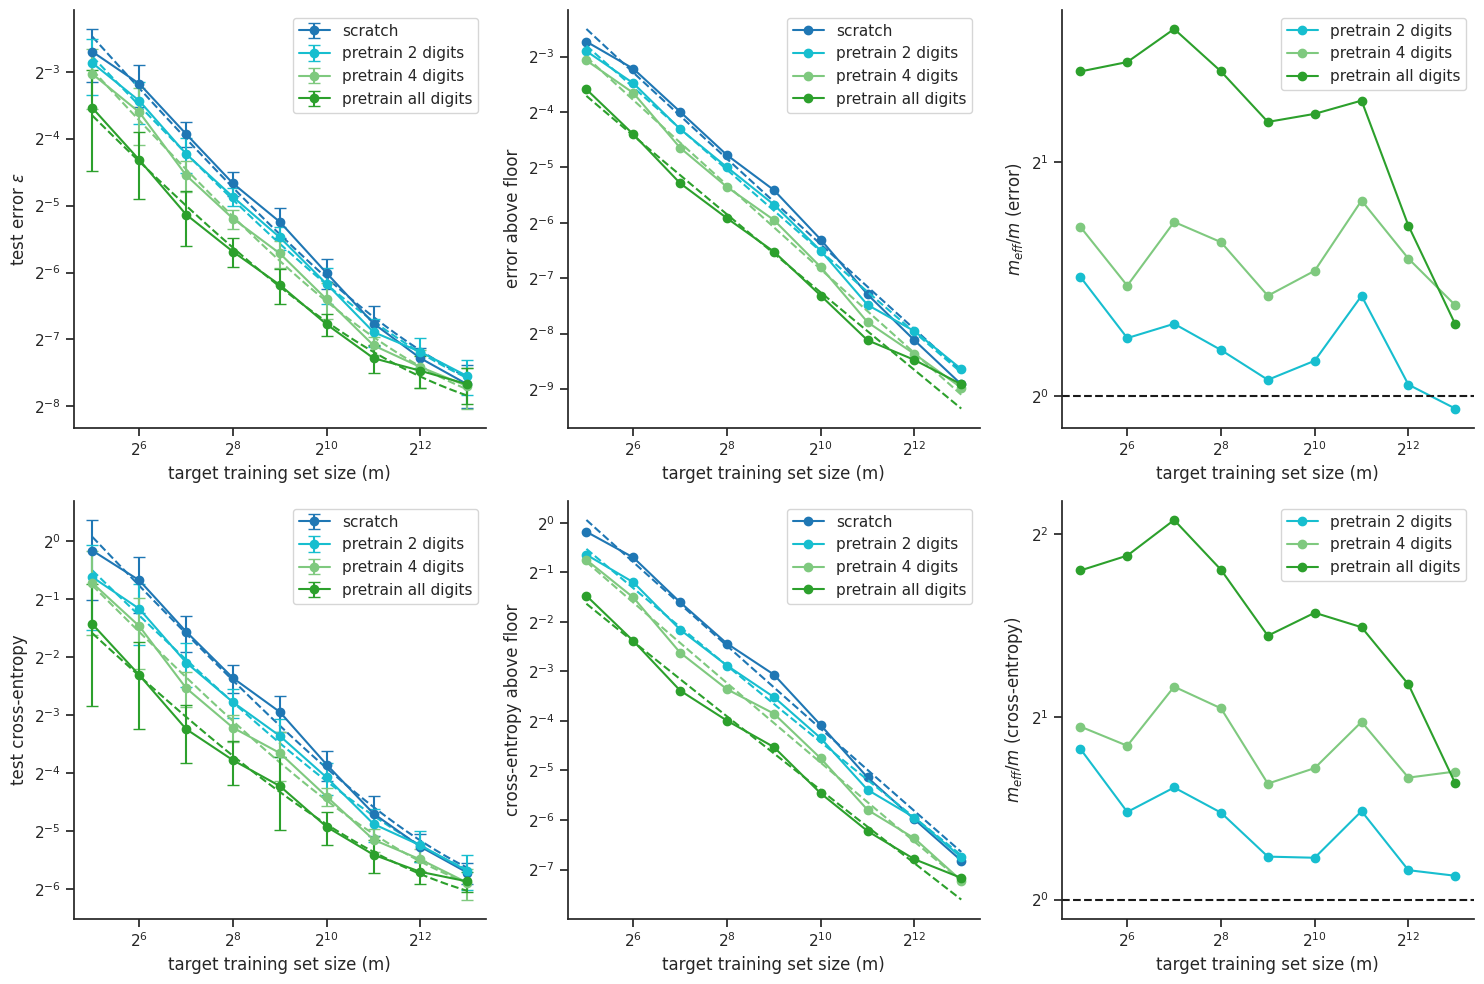

In [11]:
def loglog(ax):
    ax.set_xscale('log', base=2)
    ax.set_yscale('log', base=2)
    ax.minorticks_off()


# rows: test error, test cross-entropy
fig, axs = plt.subplots(2, 3, figsize=(15, 10))
m_grid = np.logspace(np.log2(m_lo), np.log2(m_hi), 100, base=2)
for row, (metric, (mean, sd, label)) in zip(axs, metrics.items()):
    floor, fits = floors[metric], pb_fits[metric]
    for k, cc in curves.items():
        sel, color = in_range(cc), colors[k]
        m, y = cc.train_size[sel], getattr(cc, mean)[sel]

        # data + two-part fit
        row[0].errorbar(m, y, yerr=getattr(cc, sd)[sel], color=color,
                        marker='o', markersize=6, capsize=4, label=k)
        row[0].plot(m_grid, fits[k].predict(m_grid), '--', color=color)

        # excess above the shared floor (expected curve: no error bars)
        gap = y - floor
        ok = gap > 0
        row[1].plot(m[ok], gap[ok], marker='o', markersize=6, color=color, label=k)
        row[1].plot(m_grid, fits[k].predict(m_grid) - floor, '--', color=color)

        # effective data multiplier relative to the fitted scratch curve
        if k != 'scratch':
            row[2].plot(m, invert_curve(fits['scratch'], y) / m,
                        marker='o', markersize=6, color=color, label=k)

    row[2].axhline(y=1, color='k', linestyle='--')
    row[0].set_ylabel(label)
    row[1].set_ylabel(f'{metric} above floor')
    row[2].set_ylabel(r'$m_{eff} / m$' + f' ({metric})')
    for ax in row:
        loglog(ax)
        ax.set_xlabel('target training set size (m)')
        ax.legend()

plt.tight_layout()
plt.savefig('./pretrain_curves_pacbayes.pdf', bbox_inches='tight')
plt.show()

In [12]:
import types

def bootstrap_fits(curves, sel, metric='error', n_boot=1000, seed=0):
    '''
    Bootstrap over simulation repeats: resample the repeat indices with replacement (the
    same indices for all conditions, which share the target subset of each repeat), average,
    and redo the shared-floor fit. Returns {condition: (n_boot, 2) array of (alpha, phi)}.
    '''
    per_repeat = {'error': 'errors', 'loss': 'losses'}[metric]
    rng = np.random.default_rng(seed)
    n_rep = getattr(next(iter(curves.values())), per_repeat).shape[1]

    out = {k: [] for k in curves}
    for _ in range(n_boot):
        idx = rng.integers(0, n_rep, n_rep)
        boot = {k: types.SimpleNamespace(train_size=cc.train_size,
                                         **{metric: getattr(cc, per_repeat)[:, idx].mean(axis=1)})
                for k, cc in curves.items()}
        _, fits = fit_shared_floor(boot, sel, metric=metric)
        for k, f in fits.items():
            out[k].append((f.params['alpha'], f.params['phi']))
    return {k: np.array(v) for k, v in out.items()}


boot = {metric: bootstrap_fits(curves, in_range, metric=mean) for metric, (mean, _, _) in metrics.items()}
for metric, b in boot.items():
    print(f'--- {metric}: estimate +- bootstrap sd')
    for k, v in b.items():
        p = pb_fits[metric][k].params
        print(f"{k:28s} alpha {p['alpha']:.3f} +- {v[:, 0].std():.3f}   phi {p['phi']:.3f} +- {v[:, 1].std():.3f}")

--- error: estimate +- bootstrap sd
scratch                      alpha 0.751 +- 0.038   phi 1.280 +- 0.253
pretrain 2 digits            alpha 0.718 +- 0.036   phi 0.884 +- 0.206
pretrain 4 digits            alpha 0.743 +- 0.047   phi 0.796 +- 0.217
pretrain all digits          alpha 0.691 +- 0.077   phi 0.338 +- 0.205
--- cross-entropy: estimate +- bootstrap sd
scratch                      alpha 0.806 +- 0.056   phi 11.936 +- 1.771
pretrain 2 digits            alpha 0.740 +- 0.058   phi 7.060 +- 1.605
pretrain 4 digits            alpha 0.775 +- 0.074   phi 5.817 +- 1.430
pretrain all digits          alpha 0.721 +- 0.119   phi 2.575 +- 1.245


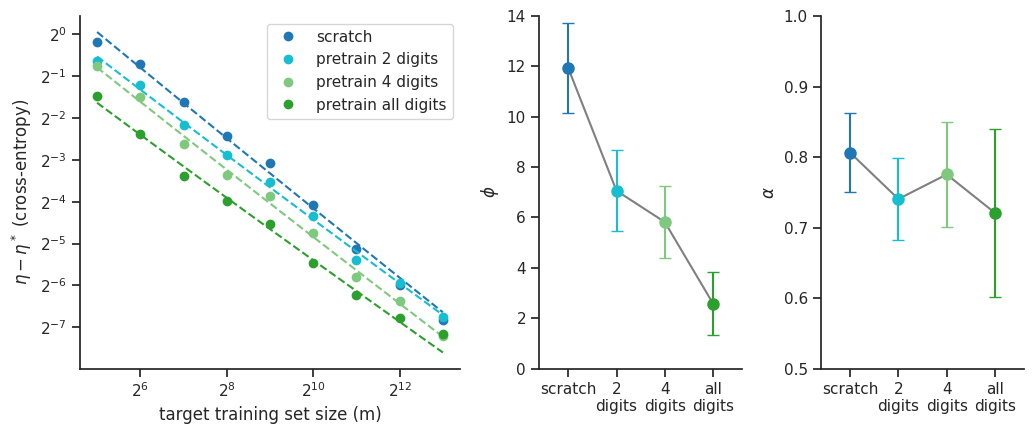

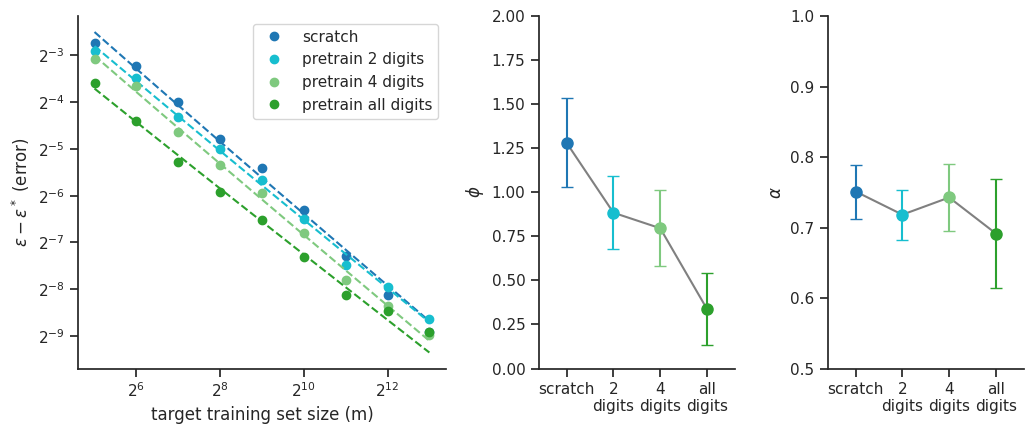

In [13]:
# paper figures: metric above the shared floor (left), fitted phi (middle) and alpha (right) +- bootstrap sd


def plot_paper(metric, ylabel, alpha_lim, phi_lim, path=None):
    mean = metrics[metric][0]
    fits, floor = pb_fits[metric], floors[metric]
    fig, axs = plt.subplots(1, 3, figsize=(10.5, 4.5), gridspec_kw={'width_ratios': [3, 1.6, 1.6]})

    # data (expected curve: no error bars) + two-part fit
    for k, cc in curves.items():
        sel, color = in_range(cc), colors[k]
        m, gap = cc.train_size[sel], getattr(cc, mean)[sel] - floor
        axs[0].plot(m, gap, marker='o', markersize=6, linestyle='none', color=color, label=k)
        axs[0].plot(m_grid, fits[k].predict(m_grid) - floor, '--', color=color)
    loglog(axs[0])
    axs[0].set_xlabel('target training set size (m)')
    axs[0].set_ylabel(ylabel)
    axs[0].legend()

    # phi (middle) and alpha (right) across conditions, +- bootstrap sd
    names = [k.replace('pretrain ', '').replace(' ', '\n') for k in curves]
    x = np.arange(len(names))
    for ax, param, label, lim in ((axs[1], 'phi', r'$\phi$', phi_lim),
                                  (axs[2], 'alpha', r'$\alpha$', alpha_lim)):
        j = ('alpha', 'phi').index(param)
        est = [fits[k].params[param] for k in curves]
        sd = [boot[metric][k][:, j].std() for k in curves]
        ax.plot(x, est, color='gray', zorder=1)
        for xi, e, s, k in zip(x, est, sd, curves):
            ax.errorbar(xi, e, yerr=s, color=colors[k], marker='o', markersize=8,
                        capsize=4, zorder=2)
        ax.set_ylim(*lim)
        ax.set_ylabel(label)
        ax.set_xticks(x, names)
        ax.set_xlim(-0.6, len(names) - 0.4)

    plt.tight_layout()
    if path is not None:
        plt.savefig(path, bbox_inches='tight')
    plt.show()


plot_paper('cross-entropy', r'$\eta - \eta^*$ (cross-entropy)', (0.5, 1.0), (0, 14),
           './pretrain_cross_entropy.pdf')
plot_paper('error', r'$\epsilon - \epsilon^*$ (error)', (0.5, 1.0), (0, 2),
           './pretrain_error.pdf')

### Example images (paper)
One training image per digit, ordered so that each (nested) pretraining set is a contiguous block:
`1, 6, 9, 0, 4, 2, 7` (nested from the right): 2 digits = {2, 7}, 4 digits = {0, 4, 2, 7},
7 digits = all seven;
the target digits 3, 5, 8 are grouped on the right (all digits = the whole row).

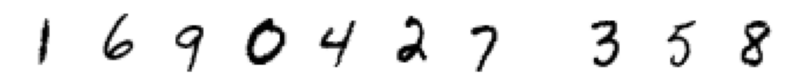

In [14]:
from torchvision import datasets

source_order = [1, 6, 9, 0, 4, 2, 7]
target_order = [3, 5, 8]

ds = datasets.MNIST('./data/vision', train=True)
X_all, y_all = ds.data.numpy() / 255.0, ds.targets.numpy()


def prototype(d, rank=0):
    # training image of digit d closest to the class mean (a typical example);
    # rank > 0 takes the next-closest ones
    X_d = X_all[y_all == d]
    return X_d[np.argsort(((X_d - X_d.mean(axis=0)) ** 2).sum(axis=(1, 2)))[rank]]


ranks = {5: 1}  # the closest 5 has a stray speck


# source digits | gap | target digits
order = source_order + [None] + target_order
fig = plt.figure(figsize=(10, 1.3))
gs = fig.add_gridspec(1, len(order), wspace=0.15,
                      width_ratios=[0.6 if d is None else 1 for d in order])
for i, d in enumerate(order):
    if d is None:
        continue
    ax = fig.add_subplot(gs[0, i])
    ax.imshow(prototype(d, ranks.get(d, 0)), cmap='gray_r')
    ax.axis('off')

plt.savefig('./digits_row.pdf', bbox_inches='tight')
plt.show()